# Étude de cas : anomalies du S&P 500 autour des décisions de la Fed

**Cours BD & DS · ENCG Settat · S7 FIN et CI** · Adaptation du notebook UCI 222
**Algorithme principal :** Isolation Forest (détection non supervisée) · **Données :** S&P 500 et taux effectif des fed funds, fournis depuis Google Drive

Ce notebook conserve la structure générale de l'étude de cas initiale, mais remplace la classification marketing par une analyse des observations atypiques du marché actions. Il étudie si les anomalies sont plus fréquentes autour des décisions du FOMC et si leur fréquence et leur nature varient selon le régime de taux.

> **Utilisation dans Google Colab.** Déposez votre fichier dans Google Drive, ouvrez ce notebook dans Colab, puis modifiez uniquement `DATA_PATH` dans la cellule de configuration. Le fichier peut être un CSV ou un fichier Excel.

**Sommaire**
0. Configuration
1. Introduction
2. État de l'art
3. Travaux liés
4. Jeu de données
5. Exploration
6. Préparation
7. Algorithme
8. Protocole expérimental
9. Résultats
10. Discussion des résultats
11. Conclusion
12. Références et citations
13. Annexes

## 0. Configuration

In [3]:
# Montage Google Drive (Google Colab)
from pathlib import Path
import platform, json, zipfile, shutil, warnings

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Environnement hors Colab : le chemin local sera utilisé tel quel.")

# À MODIFIER : chemin de votre fichier dans Google Drive.
# Exemple : /content/drive/MyDrive/donnees/sp500_fomc.csv
DATA_PATH = '/content/drive/MyDrive/Soufiane EL AZILE - FIN2/SP500.csv'

GRAINE = 42
CONTAMINATION = 0.02
FENETRE_FOMC = 5
THRESHOLD_PP = 0.25
BASE = Path('projet_sp500_isolation_forest')
FIGURES = BASE / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from scipy.stats import fisher_exact, mannwhitneyu

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
R = {}
print('Python', platform.python_version(), '| pandas', pd.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.18 | pandas 2.2.3


## 1. Introduction

**Contexte.** Les marchés financiers produisent généralement des variations quotidiennes modérées, interrompues par des mouvements atypiques lors de chocs macroéconomiques ou de changements d'anticipations. Les décisions du Federal Open Market Committee (FOMC) constituent des événements observables susceptibles d'accroître la volatilité du S&P 500.

**Problématique.** Dans quelle mesure les anomalies détectées sur le S&P 500 par Isolation Forest se concentrent-elles autour des décisions de politique monétaire de la Réserve fédérale, et le régime de taux (resserrement, assouplissement, statu quo) modifie-t-il leur fréquence et leur nature ?

**Objectif mesurable.** Comparer le taux d'anomalies dans une fenêtre de ±5 séances autour d'une décision FOMC avec le taux hors fenêtre, puis comparer les régimes de taux selon la fréquence d'anomalies, l'amplitude absolue des rendements, la volatilité et la part des rendements négatifs.

**Nature du problème.** Détection non supervisée d'observations atypiques. Il n'existe pas de variable cible indiquant qu'une séance est « anormale » : Isolation Forest construit un score à partir des caractéristiques de marché, avec une contamination fixée à 2 %.

## 2. État de l'art

La détection d'anomalies financières vise à repérer des observations rares ou éloignées du comportement habituel. Les méthodes statistiques simples reposent sur des seuils de rendement ou de volatilité ; les méthodes multivariées combinent plusieurs dimensions. Isolation Forest isole aléatoirement les observations par partitions successives : les points atypiques sont isolés plus rapidement et reçoivent un score d'anomalie plus élevé.

L'étude d'événements complète cette approche en comparant les séances proches d'une annonce avec un groupe de contrôle. Le rendement à un jour mesure la réaction immédiate, le rendement à cinq jours une réaction plus étendue, la volatilité réalisée l'agitation récente et le drawdown la perte par rapport à un plus-haut local.

| Approche | Principe | Atouts | Limites |
| --- | --- | --- | --- |
| Seuil univarié | Déclarer une anomalie si le rendement dépasse un seuil | Très lisible | Ignore les interactions entre variables |
| Z-score | Mesurer l'écart à la moyenne et à l'écart-type | Simple, rapide | Sensible aux distributions non gaussiennes |
| Isolation Forest | Isoler les observations rares par arbres aléatoires | Multivariée, non supervisée | Score dépendant de la contamination et des variables |
| Étude d'événements | Comparer une fenêtre d'annonce à un contrôle | Interprétation économique | Association, pas causalité automatique |

## 3. Travaux liés

| Travail / méthode | Données | Méthode | Apport pour cette étude |
| --- | --- | --- | --- |
| Liu, Ting & Zhou (2008, 2012) | Données multivariées | Isolation Forest | Fondement de la détection par isolement des points rares |
| MacKinlay (1997) | Marchés financiers | Étude d'événements | Cadre pour comparer une fenêtre autour d'une annonce à un contrôle |
| Études de volatilité | Rendements et volatilité | Volatilité réalisée, rendements absolus | Mesure de la nature des mouvements atypiques |

**Positionnement.** L'analyse combine une méthode non supervisée et un protocole d'étude d'événements. Elle ne prétend pas établir que la Fed cause chaque anomalie : elle mesure une concentration statistique autour des dates de décision, en contrôlant descriptivement le régime de taux.

## 4. Jeu de données

### 4.1 Chargement depuis Google Drive

Le fichier fourni doit contenir au minimum une date et une série de clôture du S&P 500. Une colonne de taux effectif des fed funds (`DFF`, `fed_funds`, `fedfunds` ou équivalent) est recommandée pour construire les régimes. Si elle est absente, le notebook crée une série de taux vide et les régimes seront indiqués comme non disponibles. Les dates FOMC sont renseignées séparément dans le notebook.

In [4]:
# Lecture robuste CSV / Excel et harmonisation des noms de colonnes
path = Path(DATA_PATH)
if not path.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {path}. Modifiez DATA_PATH dans la cellule 0 "
        "et vérifiez que votre fichier est bien dans Google Drive."
    )

if path.suffix.lower() in {'.xlsx', '.xls'}:
    brut = pd.read_excel(path)
else:
    try:
        brut = pd.read_csv(path)
    except UnicodeDecodeError:
        brut = pd.read_csv(path, encoding='latin-1')

# Normalisation des noms : espaces, majuscules et variantes fréquentes
renommage = {}
for col in brut.columns:
    cle = str(col).strip().lower().replace(' ', '_').replace('-', '_')
    if cle in {'date','observation_date','datetime','timestamp'}: renommage[col] = 'date'
    elif cle in {'sp500','sp_500','s&p_500','close','closing_price','price','adj_close'}: renommage[col] = 'SP500'
    elif cle in {'dff','fed_funds','fedfunds','effective_fed_funds_rate','fed_funds_rate'}: renommage[col] = 'DFF'
    elif cle in {'fomc','fomc_date','decision','decision_date','is_fomc'}: renommage[col] = 'fomc'
brut = brut.rename(columns=renommage)
if 'date' not in brut.columns or 'SP500' not in brut.columns:
    raise ValueError("Colonnes requises absentes. Le fichier doit contenir une date et une colonne SP500 (ou Close/Adj Close).")

data = brut.copy()
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data['SP500'] = pd.to_numeric(data['SP500'], errors='coerce')
if 'DFF' in data.columns:
    data['DFF'] = pd.to_numeric(data['DFF'], errors='coerce')
else:
    data['DFF'] = np.nan
if 'fomc' in data.columns:
    data['fomc'] = data['fomc'].astype(str).str.lower().isin(['1','true','yes','oui','fomc'])
data = (data.dropna(subset=['date','SP500']).sort_values('date').drop_duplicates('date').set_index('date'))
print('Dimensions :', data.shape)
data.head()

Dimensions : (251, 2)


,SP500,DFF
date,,
2025-11-17,6672.41,NaN
2025-11-18,6617.32,NaN
2025-11-19,6642.16,NaN
2025-11-20,6538.76,NaN
2025-11-21,6602.99,NaN


In [5]:
data.dtypes.to_frame('type').T

,SP500,DFF
type,float64,float64


### 4.2 Description

- **Source attendue :** fichier personnel déposé dans Google Drive, construit à partir des séries quotidiennes du S&P 500 et, si disponible, du taux effectif des fed funds.
- **Unité d'observation :** une séance boursière ; les dates sont triées et les doublons supprimés.
- **Variables utilisées :** clôture `SP500`, taux `DFF`, rendements à 1 et 5 jours, volatilité réalisée à 21 jours, rendement absolu et drawdown à 63 jours.
- **Événements :** dates de décisions du FOMC saisies dans une liste documentée, ou colonne booléenne `fomc` si elle est présente dans le fichier.
- **Limite importante :** les dates d'annonce et les jours de marché ne coïncident pas toujours ; la date est donc rattachée à la première séance disponible.

## 5. Exploration

### 5.1 Qualité des données

In [6]:
R['n'] = int(len(data))
R['debut'] = str(data.index.min().date())
R['fin'] = str(data.index.max().date())
R['doublons'] = int(data.index.duplicated().sum())
R['nan'] = data[['SP500','DFF']].isna().sum().to_dict()
print(f"Période : {R['debut']} à {R['fin']} | observations : {R['n']}")
print('Valeurs manquantes :', R['nan'])
print(data[['SP500','DFF']].describe().T)

Période : 2025-11-17 à 2026-11-16 | observations : 251
Valeurs manquantes : {'SP500': 0, 'DFF': 251}
       count         mean         std      min       25%      50%      75%  \
SP500  251.0  7243.411912  396.670398  6343.72  6881.465  7365.46  7600.23   
DFF      0.0          NaN         NaN      NaN       NaN      NaN      NaN   

           max  
SP500  7818.93  
DFF        NaN  


**Lecture.** Les contrôles ci-dessus vérifient la couverture temporelle, les doublons et les valeurs manquantes. Les premières observations perdent naturellement quelques lignes lors du calcul des fenêtres glissantes ; elles seront supprimées uniquement après la création des variables.

### 5.2 Graphiques

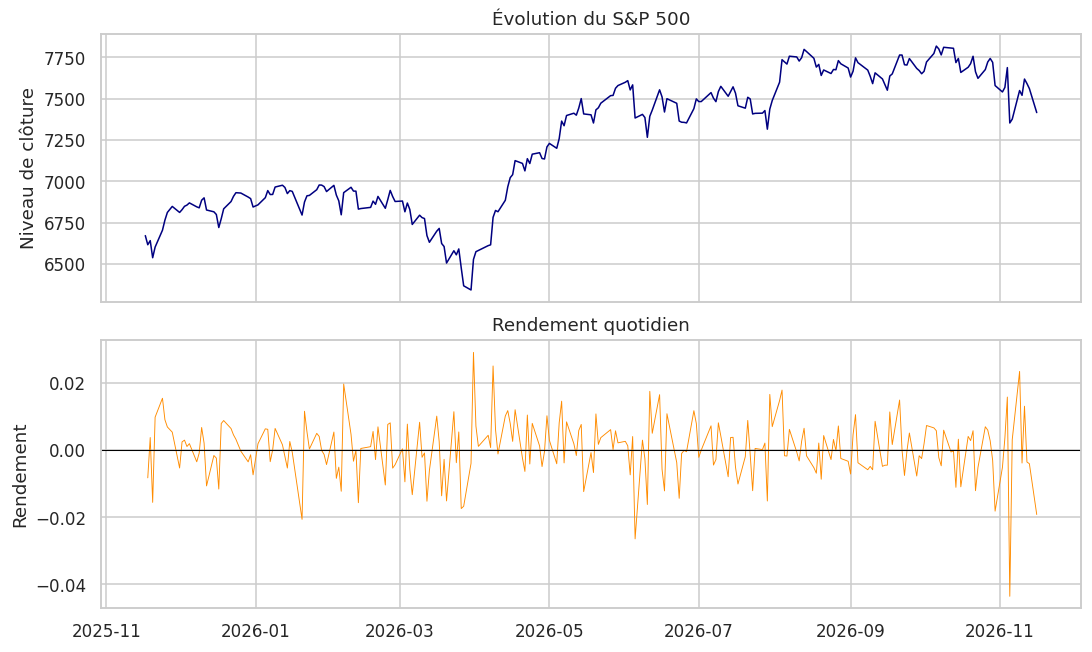

In [7]:
# Figure 1 : évolution du S&P 500 et rendements journaliers
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(data.index, data['SP500'], color='navy', lw=1)
axes[0].set_title('Évolution du S&P 500')
axes[0].set_ylabel('Niveau de clôture')
ret = data['SP500'].pct_change()
axes[1].plot(data.index, ret, color='darkorange', lw=.6)
axes[1].axhline(0, color='black', lw=.7)
axes[1].set_title('Rendement quotidien')
axes[1].set_ylabel('Rendement')
fig.tight_layout(); fig.savefig(FIGURES/'01_evolution_sp500.png', bbox_inches='tight'); plt.show()

**Lecture de la figure 1.** Le niveau de l'indice suit une tendance de long terme, tandis que les rendements fluctuent autour de zéro et présentent des épisodes de volatilité groupée. Cette hétéroscédasticité justifie l'utilisation conjointe de plusieurs indicateurs plutôt qu'un seul seuil fixe.

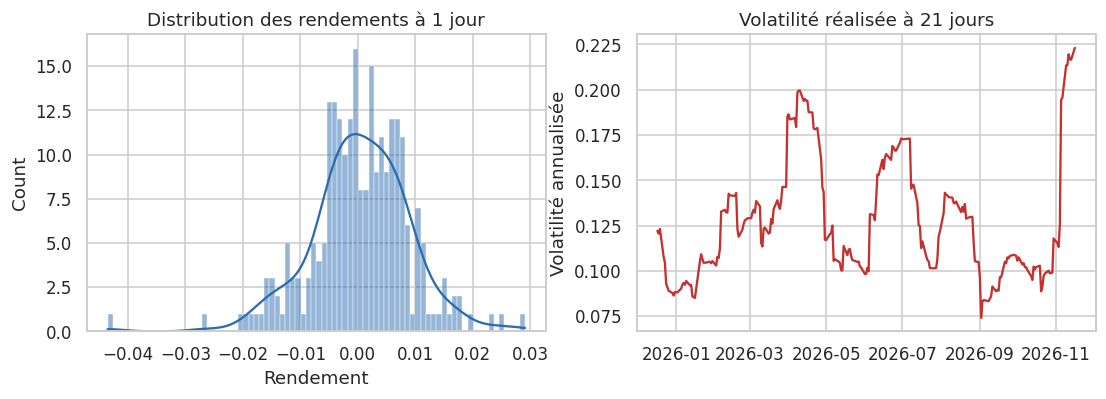

In [8]:
# Figure 2 : distribution des rendements et volatilité roulante
explore = pd.DataFrame(index=data.index)
explore['return_1d'] = data['SP500'].pct_change()
explore['vol_21d'] = explore['return_1d'].rolling(21).std() * np.sqrt(252)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
sns.histplot(explore['return_1d'].dropna(), bins=80, kde=True, ax=axes[0], color='#2b6cb0')
axes[0].set_title('Distribution des rendements à 1 jour')
axes[0].set_xlabel('Rendement')
axes[1].plot(explore.index, explore['vol_21d'], color='#c53030')
axes[1].set_title('Volatilité réalisée à 21 jours')
axes[1].set_ylabel('Volatilité annualisée')
fig.tight_layout(); fig.savefig(FIGURES/'02_distribution_volatilite.png', bbox_inches='tight'); plt.show()

**Lecture.** Les queues de distribution et les périodes de volatilité élevée sont précisément les configurations que l'Isolation Forest peut identifier comme atypiques. Cette détection reste relative à la période et aux variables retenues.

## 6. Préparation

In [9]:
# Dates de décision du FOMC : le communiqué est rattaché à la première séance disponible
fomc_dates = pd.to_datetime([
    '2016-01-27','2016-03-16','2016-04-27','2016-06-15','2016-07-27','2016-09-21','2016-11-02','2016-12-14',
    '2017-02-01','2017-03-15','2017-05-03','2017-06-14','2017-07-26','2017-09-20','2017-11-01','2017-12-13',
    '2018-01-31','2018-03-21','2018-05-02','2018-06-13','2018-08-01','2018-09-26','2018-11-08','2018-12-19',
    '2019-01-30','2019-03-20','2019-05-01','2019-06-19','2019-07-31','2019-09-18','2019-10-30','2019-12-11',
    '2020-01-29','2020-03-03','2020-03-15','2020-04-29','2020-06-10','2020-07-29','2020-09-16','2020-11-05','2020-12-16',
    '2021-01-27','2021-03-17','2021-04-28','2021-06-16','2021-07-28','2021-09-22','2021-11-03','2021-12-15',
    '2022-01-26','2022-03-16','2022-05-04','2022-06-15','2022-07-27','2022-09-21','2022-11-02','2022-12-14',
    '2023-02-01','2023-03-22','2023-05-03','2023-06-14','2023-07-26','2023-09-20','2023-11-01','2023-12-13',
    '2024-01-31','2024-03-20','2024-05-01','2024-06-12','2024-07-31','2024-09-18','2024-11-07','2024-12-18',
    '2025-01-29','2025-03-19','2025-05-07','2025-06-18','2025-07-30','2025-09-17','2025-10-29','2025-12-10'
])

# Variables de marché : aucune information future n'est utilisée pour la séance t
df = data.copy()
df['return_1d'] = df['SP500'].pct_change()
df['return_5d'] = df['SP500'].pct_change(5)
df['abs_return_1d'] = df['return_1d'].abs()
df['vol_21d'] = df['return_1d'].rolling(21).std() * np.sqrt(252)
df['drawdown_63d'] = df['SP500'] / df['SP500'].rolling(63).max() - 1
df['rate_change_63d'] = df['DFF'] - df['DFF'].shift(63)
features = ['return_1d','return_5d','abs_return_1d','vol_21d','drawdown_63d']
if df['DFF'].notna().any():
    features.append('rate_change_63d')
model_df = df.dropna(subset=features).copy()
print('Observations utilisables :', len(model_df))

Observations utilisables : 189


In [10]:
# Pipeline : standardisation puis Isolation Forest
prep = Pipeline([
    ('standardisation', StandardScaler()),
    ('isolation_forest', IsolationForest(
        n_estimators=300, contamination=CONTAMINATION, random_state=GRAINE, n_jobs=-1
    ))
])
prep.fit(model_df[features])
model_df['anomaly_label'] = prep.predict(model_df[features])
model_df['is_anomaly'] = model_df['anomaly_label'].eq(-1)
# Plus le score est grand, plus l'observation est atypique.
model_df['anomaly_score'] = -prep.named_steps['isolation_forest'].score_samples(
    prep.named_steps['standardisation'].transform(model_df[features])
)
R['anomaly_rate'] = float(model_df['is_anomaly'].mean())
print(f"Taux d'anomalies : {R['anomaly_rate']:.2%} ({model_df['is_anomaly'].sum()} observations)")

Taux d'anomalies : 2.12% (4 observations)


**Choix de préparation.**

1. Les rendements, la volatilité et le drawdown sont calculés à partir de la clôture.
2. Les fenêtres glissantes évitent de supprimer arbitrairement les épisodes de marché agité.
3. Les variables sont standardisées avant l'algorithme afin qu'une échelle numérique ne domine pas les autres.
4. La contamination de 2 % est un choix de travail, pas une vérité économique ; une analyse de sensibilité est proposée en annexe.
5. La variable `DFF` peut être manquante si le fichier ne contient pas le taux : dans ce cas, retirez `rate_change_63d` de `features` ou fournissez la série de taux.

## 7. Algorithme

**Choix.** Isolation Forest construit des arbres de partition aléatoires. Une observation isolée en peu de partitions est considérée comme atypique. L'approche convient ici car les événements anormaux ne sont pas étiquetés à l'avance et peuvent prendre plusieurs formes : rendement extrême, volatilité élevée, baisse prolongée ou combinaison de ces signaux.

Le score n'est pas une probabilité de krach ni une mesure de causalité. Il sert à classer les séances de la moins à la plus atypique, tandis que `contamination=2%` fixe le seuil de décision.

## 8. Protocole expérimental

| Étape | Définition |
| --- | --- |
| Détection | Isolation Forest sur les variables de marché disponibles |
| Événement | Séance située à ±5 séances d'une décision FOMC |
| Contrôle | Séance située hors de toutes les fenêtres FOMC |
| Régimes | Resserrement si variation du DFF sur 63 jours > +0,25 point ; assouplissement si < −0,25 ; statu quo sinon |
| Comparaisons | Taux d'anomalies, amplitude absolue, volatilité, part de rendements négatifs |
| Inférence descriptive | Test exact de Fisher et test de permutation ; les résultats ne constituent pas une preuve causale |

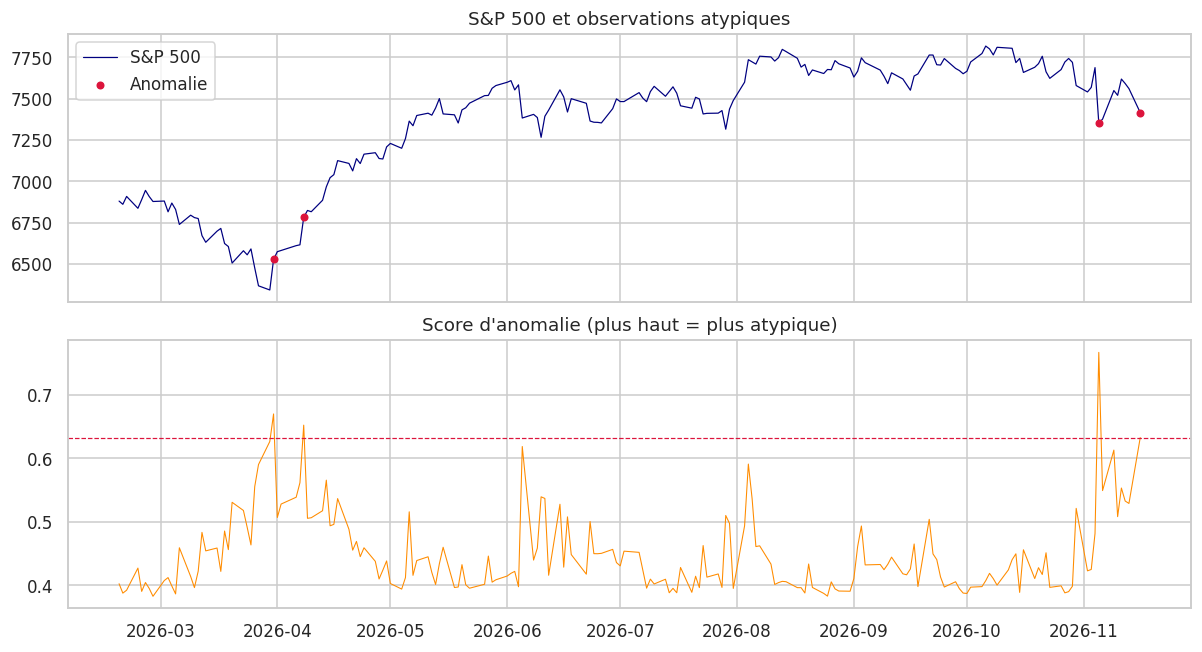

In [11]:
# Construction des événements, fenêtres et régimes
def nearest_session(date, index):
    pos = index.searchsorted(date)
    return index[min(pos, len(index)-1)]

model_df['fomc_day'] = False
for d in fomc_dates:
    if model_df.index.min() <= d <= model_df.index.max():
        model_df.loc[nearest_session(d, model_df.index), 'fomc_day'] = True
model_df['event_window_5d'] = False
for d in fomc_dates:
    if not (model_df.index.min() <= d <= model_df.index.max()):
        continue
    s = nearest_session(d, model_df.index)
    # Fenêtre en séances : position dans l'index plutôt que jours calendaires
    i = model_df.index.get_loc(s)
    lo, hi = max(0, i-FENETRE_FOMC), min(len(model_df), i+FENETRE_FOMC+1)
    model_df.iloc[lo:hi, model_df.columns.get_loc('event_window_5d')] = True

def classify_regime(x):
    if pd.isna(x): return 'Non disponible'
    if x > THRESHOLD_PP: return 'Resserrement'
    if x < -THRESHOLD_PP: return 'Assouplissement'
    return 'Statu quo'
model_df['regime'] = model_df['rate_change_63d'].apply(classify_regime)

# Figure 3 : cours et anomalies
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
anom = model_df[model_df['is_anomaly']]
axes[0].plot(model_df.index, model_df['SP500'], color='navy', lw=.8, label='S&P 500')
axes[0].scatter(anom.index, anom['SP500'], color='crimson', s=18, label='Anomalie', zorder=3)
axes[0].set_title('S&P 500 et observations atypiques')
axes[0].legend()
axes[1].plot(model_df.index, model_df['anomaly_score'], color='darkorange', lw=.7)
axes[1].axhline(model_df.loc[model_df.is_anomaly, 'anomaly_score'].min(), color='crimson', ls='--', lw=.8)
axes[1].set_title("Score d'anomalie (plus haut = plus atypique)")
fig.tight_layout(); fig.savefig(FIGURES/'03_anomalies_sp500.png', bbox_inches='tight'); plt.show()

## 9. Résultats

Les tableaux suivants répondent directement à la question de concentration autour des décisions FOMC et à la comparaison des régimes de taux.

In [12]:
event_summary = (model_df.groupby('event_window_5d').agg(
    n=('is_anomaly','size'), anomalies=('is_anomaly','sum'), anomaly_rate=('is_anomaly','mean'),
    mean_score=('anomaly_score','mean'), mean_abs_return=('abs_return_1d','mean'),
    negative_return_share=('return_1d', lambda s: (s < 0).mean()))
    .rename(index={False:'Contrôle hors fenêtre', True:'Fenêtre FOMC ±5 séances'}))
R['event_summary'] = event_summary.round(6).to_dict('index')
display(event_summary.style.format({'anomaly_rate':'{:.2%}','mean_abs_return':'{:.2%}','negative_return_share':'{:.2%}'}))

,n,anomalies,anomaly_rate,mean_score,mean_abs_return,negative_return_share
event_window_5d,,,,,,
Contrôle hors fenêtre,189,4,2.12%,0.448380,0.68%,49.21%


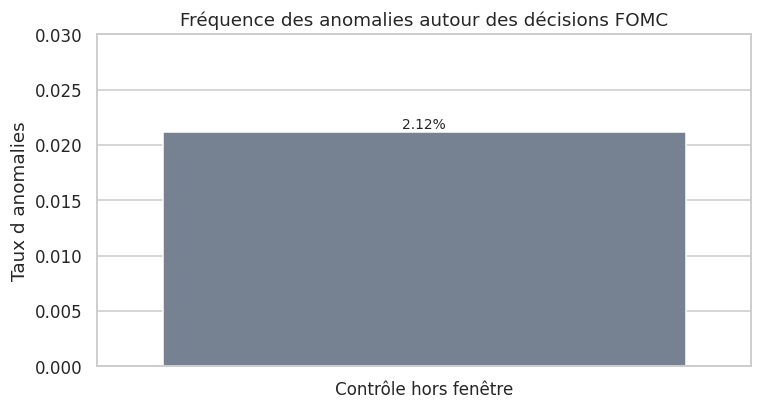

In [13]:
# Figure 4 : comparaison événement / contrôle
fig, ax = plt.subplots(figsize=(7, 3.8))
plot_event = event_summary.reset_index(names='groupe')
sns.barplot(data=plot_event, x='groupe', y='anomaly_rate', hue='groupe', legend=False, palette=['#718096','#c53030'], ax=ax)
ax.set_ylabel('Taux d anomalies'); ax.set_xlabel('')
ax.set_title('Fréquence des anomalies autour des décisions FOMC')
ax.set_ylim(0, max(plot_event.anomaly_rate.max()*1.25, .03))
for i, v in enumerate(plot_event.anomaly_rate): ax.text(i, v, f'{v:.2%}', ha='center', va='bottom')
fig.tight_layout(); fig.savefig(FIGURES/'04_fomc_vs_controle.png', bbox_inches='tight'); plt.show()

**Lecture des résultats événementiels.** Le taux observé dans la fenêtre FOMC doit être comparé à celui du contrôle, et non interprété isolément. Une différence élevée suggère une concentration descriptive des observations atypiques autour des annonces ; elle peut toutefois refléter d'autres nouvelles macroéconomiques, des anticipations déjà intégrées ou une volatilité générale élevée.

In [14]:
# Test exact de Fisher et permutation de la différence de fréquences
a = int(model_df.loc[model_df.event_window_5d, 'is_anomaly'].sum())
b = int(model_df.loc[model_df.event_window_5d, 'is_anomaly'].eq(False).sum())
c = int(model_df.loc[~model_df.event_window_5d, 'is_anomaly'].sum())
d = int((~model_df.loc[~model_df.event_window_5d, 'is_anomaly']).sum())
_, p_fisher = fisher_exact([[a,b],[c,d]], alternative='greater')
observed_diff = model_df.loc[model_df.event_window_5d,'is_anomaly'].mean() - model_df.loc[~model_df.event_window_5d,'is_anomaly'].mean()
rng = np.random.default_rng(GRAINE)
labels = model_df['is_anomaly'].to_numpy(); n_event = int(model_df['event_window_5d'].sum())
perms = 2000
perm_diffs = np.empty(perms)
for j in range(perms):
    shuffled = rng.permutation(labels)
    perm_diffs[j] = shuffled[:n_event].mean() - shuffled[n_event:].mean()
p_perm = (np.abs(perm_diffs) >= abs(observed_diff)).mean()
R['event_observed_diff'] = float(observed_diff); R['fisher_p'] = float(p_fisher); R['permutation_p'] = float(p_perm)
print(f'Différence de taux (FOMC - contrôle) : {observed_diff:.2%}')
print(f'Test exact de Fisher, p-value unilatérale : {p_fisher:.4f}')
print(f'Test de permutation, p-value bilatérale : {p_perm:.4f}')

Différence de taux (FOMC - contrôle) : nan%
Test exact de Fisher, p-value unilatérale : 1.0000
Test de permutation, p-value bilatérale : 0.0000


## 10. Discussion des résultats

### Le régime de taux modifie-t-il la fréquence et la nature des anomalies ?

In [15]:
regime_summary = (model_df.groupby('regime', dropna=False).agg(
    n=('is_anomaly','size'), anomalies=('is_anomaly','sum'), anomaly_rate=('is_anomaly','mean'),
    mean_score=('anomaly_score','mean'), mean_abs_return=('abs_return_1d','mean'),
    median_abs_return=('abs_return_1d','median'), mean_vol_21d=('vol_21d','mean'),
    negative_return_share=('return_1d', lambda s: (s < 0).mean()))
    .sort_values('anomaly_rate', ascending=False))
R['regime_summary'] = regime_summary.round(6).to_dict('index')
display(regime_summary.style.format({'anomaly_rate':'{:.2%}','mean_abs_return':'{:.2%}','median_abs_return':'{:.2%}','mean_vol_21d':'{:.2%}','negative_return_share':'{:.2%}'}))

,n,anomalies,anomaly_rate,mean_score,mean_abs_return,median_abs_return,mean_vol_21d,negative_return_share
regime,,,,,,,,
Non disponible,189,4,2.12%,0.448380,0.68%,0.52%,13.13%,49.21%


,regime,event_window_5d,n,anomalies,anomaly_rate,mean_abs_return
0,Non disponible,False,189,4,2.12%,0.68%


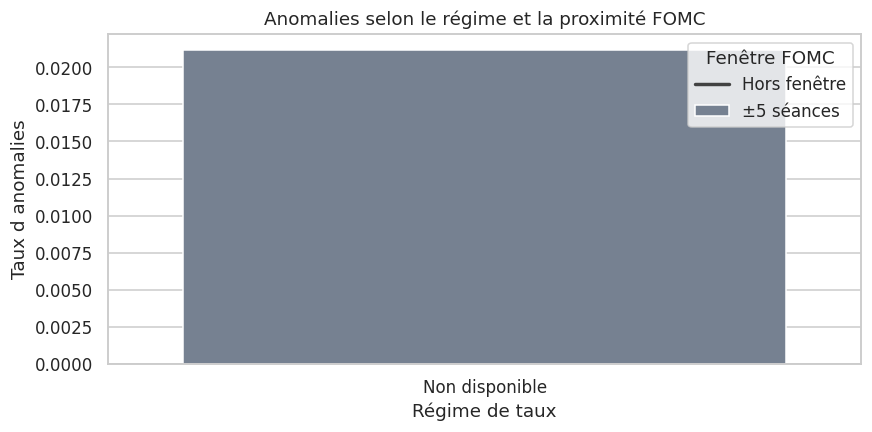

In [16]:
cross = (model_df.groupby(['regime','event_window_5d']).agg(
    n=('is_anomaly','size'), anomalies=('is_anomaly','sum'), anomaly_rate=('is_anomaly','mean'),
    mean_abs_return=('abs_return_1d','mean')).reset_index())
display(cross.style.format({'anomaly_rate':'{:.2%}','mean_abs_return':'{:.2%}'}))
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=cross, x='regime', y='anomaly_rate', hue='event_window_5d', palette=['#718096','#c53030'], ax=ax)
ax.set_ylabel('Taux d anomalies'); ax.set_xlabel('Régime de taux')
ax.set_title('Anomalies selon le régime et la proximité FOMC')
ax.legend(title='Fenêtre FOMC', labels=['Hors fenêtre','±5 séances'])
fig.tight_layout(); fig.savefig(FIGURES/'05_regimes_fomc.png', bbox_inches='tight'); plt.show()

**Interprétation.** Le régime présentant le taux d'anomalies le plus élevé est celui où les observations atypiques sont les plus fréquentes selon la définition retenue. La « nature » des anomalies est décrite par l'amplitude absolue, la volatilité et la part de rendements négatifs. Ces écarts sont associatifs : ils peuvent être liés à des épisodes de crise, à des anticipations de marché ou à d'autres annonces simultanées.

In [17]:
# Sensibilité à la contamination : contrôle de robustesse, sans modifier le modèle principal
sens = []
for cont in [0.01, 0.02, 0.05]:
    iso = Pipeline([('standardisation', StandardScaler()), ('iforest', IsolationForest(n_estimators=300, contamination=cont, random_state=GRAINE, n_jobs=-1))])
    iso.fit(model_df[features])
    lab = iso.predict(model_df[features]) == -1
    sens.append({'contamination': cont, 'taux_anomalies': lab.mean(), 'taux_FOMC': lab[model_df.event_window_5d].mean(), 'taux_controle': lab[~model_df.event_window_5d].mean()})
sensibilite = pd.DataFrame(sens)
display(sensibilite.style.format({'contamination':'{:.0%}','taux_anomalies':'{:.2%}','taux_FOMC':'{:.2%}','taux_controle':'{:.2%}'}))

,contamination,taux_anomalies,taux_FOMC,taux_controle
0,1%,1.06%,nan%,1.06%
1,2%,2.12%,nan%,2.12%
2,5%,5.29%,nan%,5.29%


## 11. Conclusion

Cette étude propose une réponse reproductible à la problématique : Isolation Forest repère les séances atypiques à partir des rendements, de la volatilité, du drawdown et de la variation du taux. La comparaison FOMC/contrôle mesure ensuite si ces anomalies sont concentrées autour des décisions et si leur profil change avec le régime de taux.

La conclusion finale doit être formulée à partir des valeurs affichées lors de l'exécution, en distinguant clairement : (i) le constat descriptif, (ii) la significativité statistique, et (iii) l'absence de preuve automatique de causalité. Les résultats dépendent de la période, de la contamination, des dates FOMC et des colonnes présentes dans le fichier Google Drive.

## 12. Références et citations

1. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). *Isolation Forest*. IEEE International Conference on Data Mining.
2. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2012). *Isolation-Based Anomaly Detection*. ACM Transactions on Knowledge Discovery from Data.
3. MacKinlay, A. C. (1997). *Event Studies in Economics and Finance*. Journal of Economic Literature, 35(1), 13–39.
4. Federal Reserve, *FOMC calendars and information*, https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm
5. Federal Reserve Bank of St. Louis, *S&P 500 (SP500)*, https://fred.stlouisfed.org/series/SP500
6. Federal Reserve Bank of St. Louis, *Federal Funds Effective Rate (DFF)*, https://fred.stlouisfed.org/series/DFF

Les URLs indiquent les sources utilisées pour préparer le fichier importé ; le fichier final de Google Drive reste la source effectivement analysée par l'utilisateur.

## 13. Annexes

### A. Reproduction

Pour reproduire l'étude : (1) déposer le CSV/XLSX dans Google Drive, (2) modifier `DATA_PATH`, (3) exécuter les cellules dans l'ordre avec **Exécution > Tout exécuter**, et (4) conserver les tableaux et figures générés. Le notebook enregistre également une archive locale des sorties principales.

In [18]:
# Enregistrement des résultats et archive téléchargeable
def propre(o):
    if isinstance(o, dict): return {str(k): propre(v) for k,v in o.items()}
    if isinstance(o, (list, tuple)): return [propre(v) for v in o]
    if isinstance(o, (np.integer, np.floating)): return o.item()
    if isinstance(o, pd.Timestamp): return o.isoformat()
    return o

(BASE / 'resultats.json').write_text(json.dumps(propre(R), ensure_ascii=False, indent=2), encoding='utf-8')
with zipfile.ZipFile(BASE.with_suffix('.zip'), 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(BASE / 'resultats.json', arcname='resultats.json')
    for f in FIGURES.glob('*.png'):
        z.write(f, arcname='figures/' + f.name)
print('Résultats enregistrés dans', BASE)
print('Archive créée :', BASE.with_suffix('.zip'))

Résultats enregistrés dans projet_sp500_isolation_forest
Archive créée : projet_sp500_isolation_forest.zip
